In [1]:
import pandas as pd
ventas_df =pd.read_csv('../data/ventas.csv')
ventas_df

,fecha,region,vendedor,producto,categoria,unidades,precio_unitario,descuento
0,2024-01-02,Oeste,Pedro Diaz,Auriculares,Accesorios,5,130,0.00
1,2024-01-02,Sur,Luis Gomez,Monitor 27,Tecnologia,14,320,0.00
2,2024-01-02,Centro,Carlos Vega,Silla Ergo,Mobiliario,1,280,0.00
3,2024-01-02,Centro,Pedro Diaz,Laptop Pro,Tecnologia,10,1200,0.00
4,2024-01-03,Sur,Elena Mora,Auriculares,Accesorios,2,130,0.10
...,...,...,...,...,...,...,...,...
1195,2024-12-30,Este,Luis Gomez,Raton Ergo,Accesorios,4,45,0.00
1196,2024-12-30,Este,Marta Ruiz,Laptop Pro,Tecnologia,13,1200,0.05
1197,2024-12-31,Oeste,Ana Torres,Monitor 27,Tecnologia,2,320,0.05
1198,2024-12-31,Norte,Ana Torres,Monitor 27,Tecnologia,6,320,0.00


In [3]:
ventas_df['importe']=ventas_df['unidades']*ventas_df['precio_unitario']
ventas_df

,fecha,region,vendedor,producto,categoria,unidades,precio_unitario,descuento,importe
0,2024-01-02,Oeste,Pedro Diaz,Auriculares,Accesorios,5,130,0.00,650
1,2024-01-02,Sur,Luis Gomez,Monitor 27,Tecnologia,14,320,0.00,4480
2,2024-01-02,Centro,Carlos Vega,Silla Ergo,Mobiliario,1,280,0.00,280
3,2024-01-02,Centro,Pedro Diaz,Laptop Pro,Tecnologia,10,1200,0.00,12000
4,2024-01-03,Sur,Elena Mora,Auriculares,Accesorios,2,130,0.10,260
...,...,...,...,...,...,...,...,...,...
1195,2024-12-30,Este,Luis Gomez,Raton Ergo,Accesorios,4,45,0.00,180
1196,2024-12-30,Este,Marta Ruiz,Laptop Pro,Tecnologia,13,1200,0.05,15600
1197,2024-12-31,Oeste,Ana Torres,Monitor 27,Tecnologia,2,320,0.05,640
1198,2024-12-31,Norte,Ana Torres,Monitor 27,Tecnologia,6,320,0.00,1920


In [7]:
ventas_df[ventas_df['region']=='Sur']['importe'].sum()

np.int64(699920)

In [8]:
ventas_df.groupby('region')['importe'].sum()

region
Centro    705695
Este      549745
Norte     862360
Oeste     626295
Sur       699920
Name: importe, dtype: int64

In [9]:
ventas_df.groupby('region')['importe'].mean()

region
Centro    2594.466912
Este      3054.138889
Norte     2827.409836
Oeste     3085.197044
Sur       2916.333333
Name: importe, dtype: float64

In [10]:
ventas_df.groupby('region')['importe'].agg(['sum','mean','median','count'])

,sum,mean,median,count
region,,,,
Centro,705695,2594.466912,1580.0,272
Este,549745,3054.138889,1740.0,180
Norte,862360,2827.409836,1400.0,305
Oeste,626295,3085.197044,1820.0,203
Sur,699920,2916.333333,1340.0,240


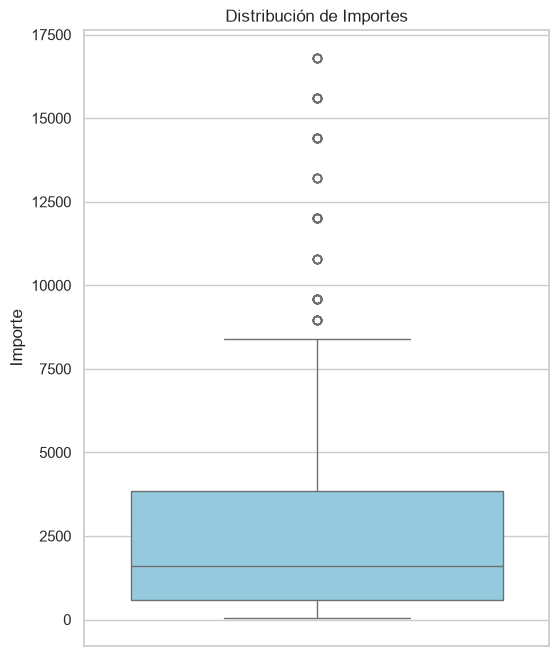

In [20]:
import seaborn as sns
import matplotlib.pyplot as plt

# Configuración de estilo
sns.set_theme(style="whitegrid")

# Crear el gráfico
plt.figure(figsize=(6, 8))
sns.boxplot(y=ventas_df['importe'], color='skyblue')

# Título
plt.title('Distribución de Importes')
plt.ylabel('Importe')

# Mostrar en pantalla
plt.show()

In [14]:
ventas_df.groupby('region')['importe'].agg(
    importe_tota='sum',
    importe_promedio='mean',
    importe_mediana='median',
    cantidad_registros='count',
    desviacion='std'
)

,importe_tota,importe_promedio,importe_mediana,cantidad_registros,desviacion
region,,,,,
Centro,705695,2594.466912,1580.0,272,2903.271820
Este,549745,3054.138889,1740.0,180,3406.026036
Norte,862360,2827.409836,1400.0,305,3434.313309
Oeste,626295,3085.197044,1820.0,203,3488.933489
Sur,699920,2916.333333,1340.0,240,3602.560150


In [15]:
ventas_df.groupby(['region','categoria'])['importe'].agg(
    importe_tota='sum',
    importe_promedio='mean',
    importe_mediana='median',
    cantidad_registros='count',
    desviacion='std'
)

importe_tota  importe_promedio  importe_mediana  \
region categoria                                                     
Centro Accesorios         56895        605.265957            495.0   
       Mobiliario        201520       2651.578947           2250.0   
       Tecnologia        447280       4385.098039           3200.0   
Este   Accesorios         44585        675.530303            555.0   
       Mobiliario        136520       2730.400000           2700.0   
       Tecnologia        368640       5760.000000           4160.0   
Norte  Accesorios         78630        639.268293            520.0   
       Mobiliario        200130       2668.400000           2250.0   
       Tecnologia        583600       5454.205607           3840.0   
Oeste  Accesorios         40205        628.203125            497.5   
       Mobiliario        156170       2692.586207           2800.0   
       Tecnologia        429920       5307.654321           3840.0   
Sur    Accesorios         57800        642.222222            530.0   
       Mobiliario        155320       2724.912281           2800.0   
       Tecnologia        486800       5234.408602           3840.0   

                   cantidad_registros   desviacion  
region categoria                                    
Centro Accesorios                  94   492.486213  
       Mobiliario                  76  1693.423399  
       Tecnologia                 102  3652.444928  
Este   Accesorios                  66   463.346629  
       Mobiliario                  50  1500.319639  
       Tecnologia                  64  4188.207178  
Norte  Accesorios                 123   474.446910  
       Mobiliario                  75  1541.673398  
       Tecnologia                 107  4400.971599  
Oeste  Accesorios                  64   462.041164  
       Mobiliario                  58  1594.353590  
       Tecnologia                  81  4337.559876  
Sur    Accesorios                  90   439.515253  
       Mobiliario                  57  1832.328849  
       Tecnologia                  93  4579.461109

In [19]:
ventas_df.groupby('region').agg({
    'importe':['sum','mean','max'],
    'unidades':['sum'],
    'producto':['nunique'], #función de unicos
})

importe                     unidades producto
           sum         mean    max      sum  nunique
region                                              
Centro  705695  2594.466912  15600     1933        8
Este    549745  3054.138889  16800     1384        8
Norte   862360  2827.409836  16800     2166        8
Oeste   626295  3085.197044  15600     1469        8
Sur     699920  2916.333333  16800     1779        8